# A simple example 

In [2]:
# ================================================================
# DYNAMIC STOCHASTIC BLOCK MODEL
# ---------------------------------------------------------------
# Experimento:
#
#   1. Generamos una red dinámica a partir de un modelo conocido.
#   2. Ocultamos las comunidades verdaderas.
#   3. Inferimos las comunidades mediante Gibbs sampling.
#   4. Inferimos la matriz de transición Markoviana P.
#   5. Inferimos la matriz de bloques Theta.
#   6. Comparamos las estimaciones con los valores verdaderos.
#
# Modelo:
#   Z_i1 ~ Categorical(pi)
#   P_r ~ Dirichlet(alpha_r)
#   Z_i,t+1 | Z_i,t=r ~ Categorical(P_r)
#   theta_kl ~ Beta(a, b)
#   A_ijt | Z_it=k, Z_jt=l ~ Bernoulli(theta_kl)
#
# ================================================================

import numpy as np
import matplotlib.pyplot as plt

from scipy.special import logsumexp
from sklearn.metrics import adjusted_rand_score

In [3]:
# 1. PARÁMETROS DEL EXPERIMENTO

# Número de nodos
N = 30

# Número de instantes temporales
T = 20

# Número de comunidades
K = 3

# Semilla para reproducibilidad
SEED = 123

rng = np.random.default_rng(SEED)

In [4]:
# 2. PARÁMETROS VERDADEROS DEL MODELO

# ------------------------------------------------
# Distribución inicial de las comunidades
# ------------------------------------------------
#
# Todos los nodos tienen la misma probabilidad de
# comenzar en cualquiera de las tres comunidades.
#
# pi = (1/3, 1/3, 1/3)
# ------------------------------------------------

pi_true = np.array([1/3, 1/3, 1/3])


# ------------------------------------------------
# Matriz de transición de las comunidades
# ------------------------------------------------
#
# P[r, s] =
# P(Z_{i,t+1}=s | Z_{it}=r)
#
# La diagonal es grande, por lo que las comunidades
# presentan persistencia temporal.
# ------------------------------------------------

P_true = np.array([
    [0.90, 0.07, 0.03],
    [0.05, 0.90, 0.05],
    [0.03, 0.07, 0.90]
])


# ------------------------------------------------
# Matriz Theta del SBM
# ------------------------------------------------
#
# Theta[k, l] =
# P(A_ijt = 1 | Z_it=k, Z_jt=l)
#
# Los valores diagonales son altos:
#
#     theta_11 = 0.60
#     theta_22 = 0.55
#     theta_33 = 0.65
#
# Por tanto, esperamos más conexiones dentro
# de las comunidades que entre comunidades.
# ------------------------------------------------

Theta_true = np.array([
    [0.60, 0.08, 0.05],
    [0.08, 0.55, 0.10],
    [0.05, 0.10, 0.65]
])


In [5]:
# 3. GENERACIÓN DE LAS COMUNIDADES DINÁMICAS

def generate_communities(N, T, K, pi, P, rng):
    """
    Genera las asignaciones comunitarias Z.

    Parámetros
    ----------
    N : int
        Número de nodos.

    T : int
        Número de instantes temporales.

    K : int
        Número de comunidades.

    pi : array
        Distribución inicial sobre las comunidades.

    P : array (K x K)
        Matriz de transición de la cadena de Markov.

    rng : numpy random generator
        Generador aleatorio.

    Retorna
    -------
    Z : array (N x T)
        Z[i, t] es la comunidad del nodo i
        en el instante t.
    """

    # Matriz que almacenará las comunidades.
    #
    # Z[i, t] ∈ {0, ..., K-1}
    Z = np.zeros((N, T), dtype=int)


    # ------------------------------------------------------------
    # Estado inicial
    # ------------------------------------------------------------

    for i in range(N):

        Z[i, 0] = rng.choice(
            K,
            p=pi
        )


    # ------------------------------------------------------------
    # Evolución temporal
    # ------------------------------------------------------------

    for t in range(1, T):

        for i in range(N):

            # Comunidad actual
            r = Z[i, t-1]

            # Distribución de la siguiente comunidad
            transition_probabilities = P[r]

            # Muestreamos la nueva comunidad
            Z[i, t] = rng.choice(
                K,
                p=transition_probabilities
            )

    return Z


In [6]:
# 4. GENERACIÓN DE LAS REDES
def generate_networks(Z, Theta, rng):
    """
    Genera las matrices de adyacencia A_t.

    Se supone una red no dirigida sin auto-enlaces.

    A[i,j,t] ~ Bernoulli(Theta[Z[i,t], Z[j,t]])

    Parámetros
    ----------
    Z : array (N x T)
        Comunidades verdaderas.

    Theta : array (K x K)
        Probabilidades de conexión entre comunidades.

    rng : numpy random generator

    Retorna
    -------
    A : array (T x N x N)

        A[t,i,j] = 1 si existe una conexión
        entre i y j en el tiempo t.
    """

    N, T = Z.shape

    A = np.zeros(
        (T, N, N),
        dtype=int
    )


    for t in range(T):

        for i in range(N):

            for j in range(i + 1, N):

                # Comunidades de los dos nodos
                k = Z[i, t]
                l = Z[j, t]

                # Probabilidad de conexión
                p = Theta[k, l]

                # Generamos la arista
                edge = rng.binomial(
                    n=1,
                    p=p
                )

                # Red no dirigida:
                A[t, i, j] = edge
                A[t, j, i] = edge

    return A


In [7]:
# 5. GENERAMOS LOS DATOS

Z_true = generate_communities(
    N=N,
    T=T,
    K=K,
    pi=pi_true,
    P=P_true,
    rng=rng
)


A = generate_networks(
    Z=Z_true,
    Theta=Theta_true,
    rng=rng
)


print("Datos generados.")
print()
print("N =", N)
print("T =", T)
print("K =", K)

Datos generados.

N = 30
T = 20
K = 3


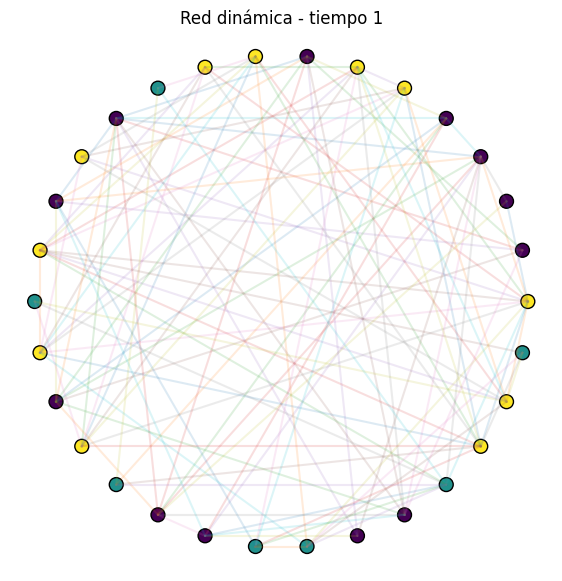

In [8]:
# 6. VISUALIZACIÓN DE UNA RED

def plot_network(A_t, Z_t, title):
    """
    Visualiza una red en un instante temporal.

    Los nodos se agrupan visualmente según su comunidad.
    """

    N = len(Z_t)

    # Distribuimos los nodos en un círculo
    angles = np.linspace(
        0,
        2*np.pi,
        N,
        endpoint=False
    )

    x = np.cos(angles)
    y = np.sin(angles)


    plt.figure(figsize=(7, 7))


    # ------------------------------------------------------------
    # Dibujar aristas
    # ------------------------------------------------------------

    for i in range(N):

        for j in range(i + 1, N):

            if A_t[i, j] == 1:

                plt.plot(
                    [x[i], x[j]],
                    [y[i], y[j]],
                    alpha=0.15
                )


    # ------------------------------------------------------------
    # Dibujar nodos
    # ------------------------------------------------------------

    plt.scatter(
        x,
        y,
        c=Z_t,
        s=100,
        edgecolor="black"
    )


    plt.title(title)
    plt.axis("off")
    plt.show()


plot_network(
    A[0],
    Z_true[:, 0],
    "Red dinámica - tiempo 1"
)


In [9]:
# 7. FUNCIONES AUXILIARES PARA GIBBS

def sample_categorical(probabilities, rng):
    """
    Muestra una categoría a partir de un vector
    de probabilidades.
    """

    probabilities = np.asarray(probabilities)

    return rng.choice(
        len(probabilities),
        p=probabilities
    )



Comenzando Gibbs sampler...
Iteración 500/3000
Iteración 1000/3000
Iteración 1500/3000
Iteración 2000/3000
Iteración 2500/3000
Iteración 3000/3000
Gibbs terminado.

Número de muestras posteriores:
400

MATRIZ P VERDADERA
[[0.9  0.07 0.03]
 [0.05 0.9  0.05]
 [0.03 0.07 0.9 ]]

MATRIZ P ESTIMADA
[[0.561 0.249 0.191]
 [0.271 0.445 0.284]
 [0.085 0.237 0.678]]

THETA VERDADERA
[[0.6  0.08 0.05]
 [0.08 0.55 0.1 ]
 [0.05 0.1  0.65]]

THETA ESTIMADA
[[0.559 0.075 0.074]
 [0.074 0.653 0.058]
 [0.074 0.058 0.627]]

RECUPERACIÓN DE COMUNIDADES
ARI promedio = 0.102


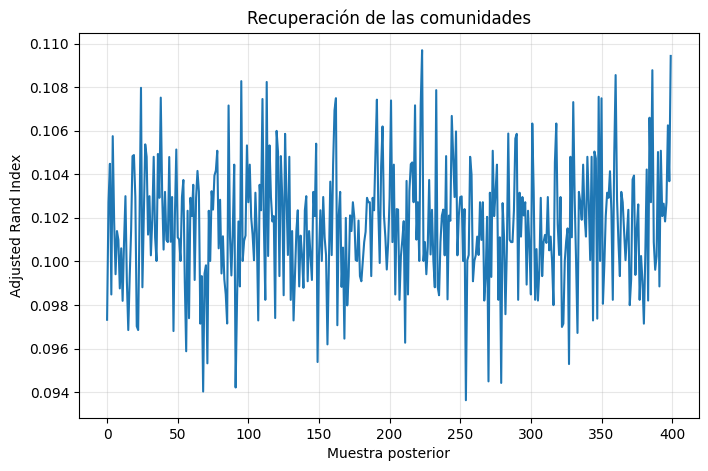


ERROR ABSOLUTO MEDIO EN P
MAE(P) = 0.2259

ERROR ABSOLUTO MEDIO EN THETA
MAE(Theta) = 0.0344


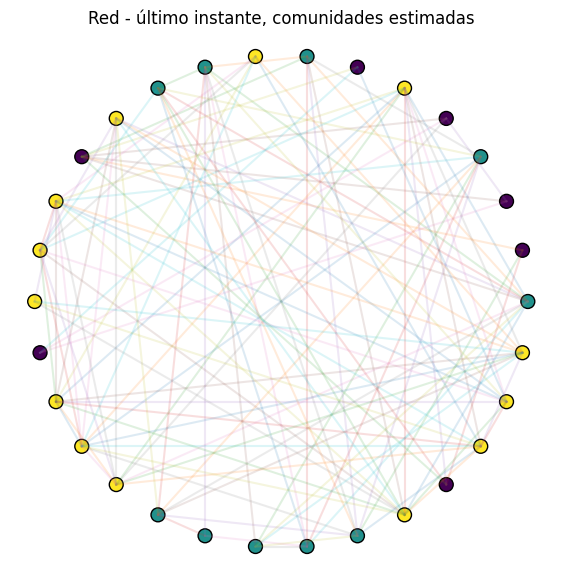

In [10]:
# 8. CÁLCULO DE LA PROBABILIDAD DE UNA ASIGNACIÓN
def log_probability_Z(
    i,
    t,
    k,
    Z,
    A,
    P,
    Theta
):
    """
    Calcula, salvo una constante, el logaritmo de

        P(Z_it = k | resto)

    utilizando tres fuentes de información:

        1. transición desde el pasado,
        2. transición hacia el futuro,
        3. estructura de la red.

    Es decir:

        posterior ∝ pasado × futuro × likelihood de red
    """

    N, T = Z.shape

    log_prob = 0.0


    # ============================================================
    # 1. INFORMACIÓN TEMPORAL: PASADO
    # ============================================================

    if t > 0:

        previous_state = Z[i, t-1]

        probability = P[
            previous_state,
            k
        ]

        # Evitamos log(0)
        if probability <= 0:
            return -np.inf

        log_prob += np.log(probability)


    # ============================================================
    # 2. INFORMACIÓN TEMPORAL: FUTURO
    # ============================================================

    if t < T - 1:

        next_state = Z[i, t+1]

        probability = P[
            k,
            next_state
        ]

        if probability <= 0:
            return -np.inf

        log_prob += np.log(probability)


    # ============================================================
    # 3. INFORMACIÓN DE LA RED
    # ============================================================
    #
    # El nodo i se conecta con todos los demás nodos.
    #
    # Para cada j observamos:
    #
    # A[i,j,t]
    #
    # y conocemos temporalmente la asignación actual de j:
    #
    # Z[j,t]
    #
    # Si proponemos Z[i,t] = k, entonces:
    #
    # P(A[i,j,t] | k, Z[j,t], Theta)
    #
    # se obtiene mediante un Bernoulli.
    # ============================================================

    for j in range(N):

        # No existe auto-enlace
        if i == j:
            continue

        l = Z[j, t]

        p = Theta[k, l]

        edge = A[t, i, j]

        if edge == 1:

            if p <= 0:
                return -np.inf

            log_prob += np.log(p)

        else:

            if p >= 1:
                return -np.inf

            log_prob += np.log(1 - p)


    return log_prob


# ================================================================
# 9. ACTUALIZACIÓN GIBBS DE Z
# ================================================================

def sample_Z(
    Z,
    A,
    P,
    Theta,
    rng
):
    """
    Actualiza todas las variables latentes Z_it
    mediante Gibbs sampling.

    Para cada nodo i y tiempo t:

        1. Probamos cada comunidad k.
        2. Calculamos log P(Z_it=k | resto).
        3. Normalizamos las probabilidades.
        4. Muestreamos una nueva comunidad.

    Retorna
    -------
    Z : array actualizado
    """

    N, T = Z.shape


    for i in range(N):

        for t in range(T):

            log_probs = np.zeros(K)


            # ----------------------------------------------------
            # Calculamos la probabilidad de cada posible comunidad
            # ----------------------------------------------------

            for k in range(K):

                log_probs[k] = log_probability_Z(
                    i=i,
                    t=t,
                    k=k,
                    Z=Z,
                    A=A,
                    P=P,
                    Theta=Theta
                )


            # ----------------------------------------------------
            # Normalización numéricamente estable
            #
            # p_k = exp(log p_k) / sum_j exp(log p_j)
            #
            # Utilizamos logsumexp para evitar problemas numéricos.
            # ----------------------------------------------------

            normalization = logsumexp(log_probs)

            probabilities = np.exp(
                log_probs - normalization
            )


            # ----------------------------------------------------
            # Muestreamos nueva comunidad
            # ----------------------------------------------------

            Z[i, t] = rng.choice(
                K,
                p=probabilities
            )

    return Z


# ================================================================
# 10. CONTAR TRANSICIONES ENTRE COMUNIDADES
# ================================================================

def transition_counts(Z, K):
    """
    Calcula los conteos:

        N_rs = número de transiciones
               r -> s

    a través de todos los nodos y tiempos.
    """

    N, T = Z.shape

    counts = np.zeros(
        (K, K),
        dtype=int
    )


    for i in range(N):

        for t in range(T - 1):

            r = Z[i, t]
            s = Z[i, t+1]

            counts[r, s] += 1


    return counts


# ================================================================
# 11. ACTUALIZACIÓN DE P MEDIANTE CONJUGACIÓN
# ================================================================

def sample_P(
    Z,
    alpha,
    rng
):
    """
    Actualiza la matriz de transición P.

    Para cada comunidad r:

        P_r ~ Dirichlet(
            alpha_r + N_r1,
            ...,
            alpha_r + N_rK
        )

    Esto es exactamente la conjugación:

        Dirichlet + Multinomial.
    """

    counts = transition_counts(
        Z,
        K
    )


    P_new = np.zeros(
        (K, K)
    )


    for r in range(K):

        posterior_alpha = (
            alpha[r]
            + counts[r]
        )

        P_new[r] = rng.dirichlet(
            posterior_alpha
        )


    return P_new


# ================================================================
# 12. CONTAR ENLACES POR BLOQUE
# ================================================================

def block_counts(Z, A, K):
    """
    Calcula para cada par de comunidades (k,l):

        E_kl = número de enlaces
        F_kl = número de no-enlaces

    Se considera una red no dirigida y, por tanto,
    solamente utilizamos i < j.
    """

    N, T = Z.shape

    edges = np.zeros(
        (K, K),
        dtype=int
    )

    non_edges = np.zeros(
        (K, K),
        dtype=int
    )


    for t in range(T):

        for i in range(N):

            for j in range(i + 1, N):

                k = Z[i, t]
                l = Z[j, t]

                if A[t, i, j] == 1:

                    edges[k, l] += 1

                    # Como la red es no dirigida,
                    # (k,l) y (l,k) representan
                    # el mismo bloque.
                    if k != l:
                        edges[l, k] += 1

                else:

                    non_edges[k, l] += 1

                    if k != l:
                        non_edges[l, k] += 1


    return edges, non_edges


# ================================================================
# 13. ACTUALIZACIÓN DE THETA
# ================================================================

def sample_Theta(
    Z,
    A,
    a_prior,
    b_prior,
    rng
):
    """
    Actualiza Theta utilizando la conjugación:

        Beta + Bernoulli.

    Para cada bloque (k,l):

        theta_kl | datos
        ~ Beta(
            a + E_kl,
            b + F_kl
        )
    """

    edges, non_edges = block_counts(
        Z,
        A,
        K
    )


    Theta_new = np.zeros(
        (K, K)
    )


    for k in range(K):

        for l in range(K):

            posterior_a = (
                a_prior
                + edges[k, l]
            )

            posterior_b = (
                b_prior
                + non_edges[k, l]
            )

            Theta_new[k, l] = rng.beta(
                posterior_a,
                posterior_b
            )


    return Theta_new


# ================================================================
# 14. INICIALIZACIÓN DEL GIBBS SAMPLER
# ================================================================

# ------------------------------------------------
# Inicialización aleatoria de Z
# ------------------------------------------------

Z_current = rng.integers(
    low=0,
    high=K,
    size=(N, T)
)


# ------------------------------------------------
# Priors
# ------------------------------------------------

# Prior Dirichlet para cada fila de P.
#
# alpha = (1,1,1) representa un prior uniforme.
# ------------------------------------------------

alpha = np.ones(
    (K, K)
)


# ------------------------------------------------
# Prior Beta para Theta
#
# Beta(1,1) = uniforme en [0,1].
# ------------------------------------------------

a_prior = 1.0
b_prior = 1.0


# ------------------------------------------------
# Inicializamos P y Theta
# ------------------------------------------------

P_current = np.ones(
    (K, K)
) / K


Theta_current = np.ones(
    (K, K)
) * 0.2


# ================================================================
# 15. GIBBS SAMPLER
# ================================================================

# Número de iteraciones
N_ITER = 3000

# Burn-in
BURN_IN = 1000

# Guardamos una muestra cada cierto número de iteraciones
THIN = 5


# Listas donde almacenaremos las muestras
Z_samples = []
P_samples = []
Theta_samples = []


print()
print("Comenzando Gibbs sampler...")


for iteration in range(N_ITER):


    # ============================================================
    # PASO 1:
    # Actualizamos las comunidades Z
    # ============================================================

    Z_current = sample_Z(
        Z=Z_current,
        A=A,
        P=P_current,
        Theta=Theta_current,
        rng=rng
    )


    # ============================================================
    # PASO 2:
    # Actualizamos P
    #
    # Dirichlet-Multinomial conjugacy
    # ============================================================

    P_current = sample_P(
        Z=Z_current,
        alpha=alpha,
        rng=rng
    )


    # ============================================================
    # PASO 3:
    # Actualizamos Theta
    #
    # Beta-Bernoulli conjugacy
    # ============================================================

    Theta_current = sample_Theta(
        Z=Z_current,
        A=A,
        a_prior=a_prior,
        b_prior=b_prior,
        rng=rng
    )


    # ============================================================
    # GUARDAMOS LA MUESTRA
    # ============================================================

    if (
        iteration >= BURN_IN
        and
        (iteration - BURN_IN) % THIN == 0
    ):

        Z_samples.append(
            Z_current.copy()
        )

        P_samples.append(
            P_current.copy()
        )

        Theta_samples.append(
            Theta_current.copy()
        )


    # ------------------------------------------------------------
    # Progreso
    # ------------------------------------------------------------

    if (iteration + 1) % 500 == 0:

        print(
            f"Iteración {iteration + 1}/{N_ITER}"
        )


print("Gibbs terminado.")


# ================================================================
# 16. CONVERTIMOS LAS MUESTRAS A ARRAYS
# ================================================================

Z_samples = np.array(
    Z_samples
)

P_samples = np.array(
    P_samples
)

Theta_samples = np.array(
    Theta_samples
)


print()
print("Número de muestras posteriores:")
print(len(P_samples))


# ================================================================
# 17. ESTIMACIÓN POSTERIOR DE P
# ================================================================

P_estimated = np.mean(
    P_samples,
    axis=0
)


# ================================================================
# 18. ESTIMACIÓN POSTERIOR DE THETA
# ================================================================

Theta_estimated = np.mean(
    Theta_samples,
    axis=0
)


# ================================================================
# 19. MOSTRAMOS LOS RESULTADOS
# ================================================================

np.set_printoptions(
    precision=3,
    suppress=True
)

print()
print("======================================")
print("MATRIZ P VERDADERA")
print("======================================")

print(P_true)


print()
print("======================================")
print("MATRIZ P ESTIMADA")
print("======================================")

print(P_estimated)


print()
print("======================================")
print("THETA VERDADERA")
print("======================================")

print(Theta_true)


print()
print("======================================")
print("THETA ESTIMADA")
print("======================================")

print(Theta_estimated)


# ================================================================
# 20. PROBLEMA DE LABEL SWITCHING
# ================================================================
#
# IMPORTANTE:
#
# El Gibbs sampler no sabe que nuestra comunidad "0"
# es la comunidad "0" verdadera.
#
# Puede encontrar exactamente la misma partición pero
# intercambiando las etiquetas.
#
# Por ejemplo:
#
# verdad:
#       0 0 0 1 1 1 2 2 2
#
# MCMC:
#       2 2 2 0 0 0 1 1 1
#
# Estadísticamente son la misma partición.
#
# Para medir recuperación de comunidades usamos
# Adjusted Rand Index (ARI), que no depende de las etiquetas.
# ================================================================


ARI_samples = []


for Z_sample in Z_samples:

    ari = adjusted_rand_score(
        Z_true.flatten(),
        Z_sample.flatten()
    )

    ARI_samples.append(
        ari
    )


mean_ARI = np.mean(
    ARI_samples
)


print()
print("======================================")
print("RECUPERACIÓN DE COMUNIDADES")
print("======================================")

print(
    f"ARI promedio = {mean_ARI:.3f}"
)


# ================================================================
# 21. EVOLUCIÓN DEL ARI
# ================================================================

plt.figure(figsize=(8, 5))

plt.plot(
    ARI_samples
)

plt.xlabel("Muestra posterior")
plt.ylabel("Adjusted Rand Index")
plt.title("Recuperación de las comunidades")

plt.grid(alpha=0.3)

plt.show()


# ================================================================
# 22. COMPARACIÓN DE P
# ================================================================

print()
print("======================================")
print("ERROR ABSOLUTO MEDIO EN P")
print("======================================")

P_error = np.mean(
    np.abs(
        P_estimated - P_true
    )
)

print(
    f"MAE(P) = {P_error:.4f}"
)


# ================================================================
# 23. COMPARACIÓN DE THETA
# ================================================================

print()
print("======================================")
print("ERROR ABSOLUTO MEDIO EN THETA")
print("======================================")

Theta_error = np.mean(
    np.abs(
        Theta_estimated - Theta_true
    )
)

print(
    f"MAE(Theta) = {Theta_error:.4f}"
)


# ================================================================
# 24. VISUALIZAR UNA RED ESTIMADA
# ================================================================
#
# Tomamos la asignación de la última muestra posterior.
#
# NOTA:
# Debido a label switching, esta visualización no necesariamente
# tendrá los mismos números de comunidad que Z_true.
# ================================================================

Z_last = Z_samples[-1]


plot_network(
    A[-1],
    Z_last[:, -1],
    "Red - último instante, comunidades estimadas"
)